### Dynamics with the Average Connectivity Matrix

In [4]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "average_connectivity_20seeds").exists():
    ROOT = Path(r"C:\Users\aceve\Desktop\HeterogeneousRNNs\new_initial_conditions\positive_currents\positive_currents_ordered")
RESULTS = ROOT / "average_connectivity_20seeds"
OUTPUT = RESULTS / "plots"
OUTPUT.mkdir(exist_ok=True)
AMPLITUDES = [2, 4, 8, 12, 16, 20]
GSYNS = [0.1, 0.5, 1, 2]
PQIFS = [0, 0.5, 1]
ITSTIM, ITMAX = 200, 1000


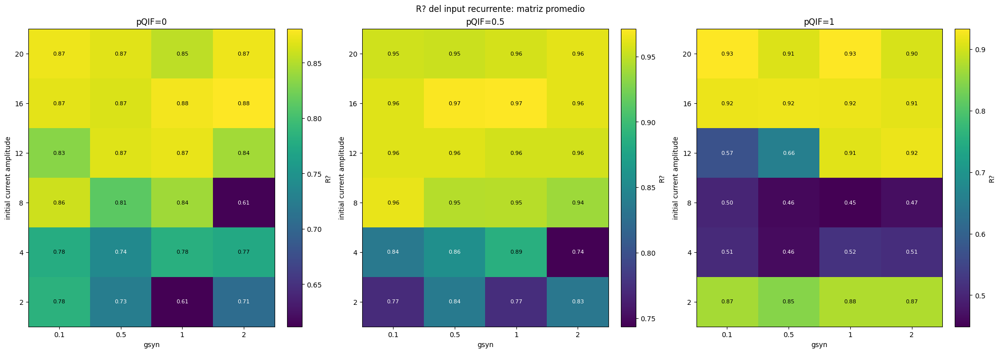

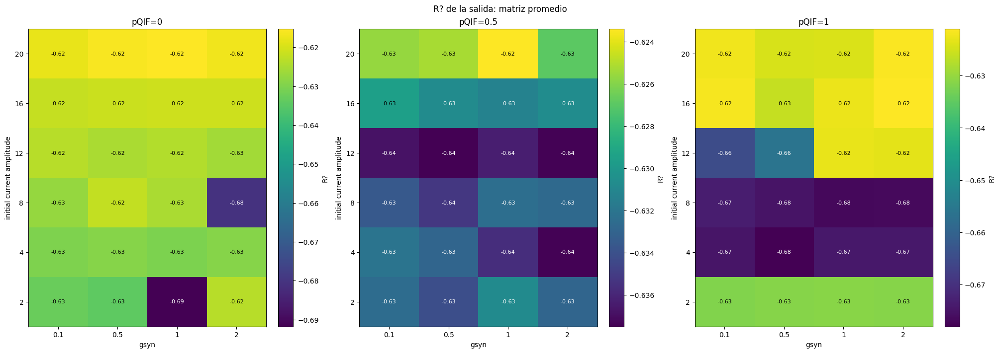

In [5]:
r2 = pd.read_csv(RESULTS / "average_dynamics_r2.csv")

def source_dir(amplitude, gsyn):
    return RESULTS / f"ampc_{amplitude:g}_g{gsyn:g}"

def sequence_order(amplitude, gsyn):
    source = ROOT / f"seeds_20_ampc_{amplitude:g}_g{gsyn:g}" / "condition_000" / "target_parameters.csv"
    with source.open(newline="") as file:
        rows = list(csv.DictReader(file))
    return np.array([int(row["neuron_index"]) for row in sorted(rows, key=lambda row: float(row["sequence_position"]))])

def r2_matrix(pqif, column):
    data = r2[r2.pqif == pqif]
    return (data.pivot(index="current_amplitude", columns="gsyn", values=column)
            .reindex(index=AMPLITUDES, columns=GSYNS).to_numpy())

def draw_grid(column, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(20, 7), constrained_layout=True)
    for ax, pqif in zip(axes, PQIFS):
        values = r2_matrix(pqif, column)
        image = ax.imshow(values, origin="lower", aspect="auto", cmap="viridis",
                          vmin=np.nanmin(values), vmax=np.nanmax(values))
        ax.set_xticks(range(len(GSYNS)), [f"{x:g}" for x in GSYNS])
        ax.set_yticks(range(len(AMPLITUDES)), [f"{x:g}" for x in AMPLITUDES])
        ax.set_xlabel("gsyn")
        ax.set_ylabel("initial current amplitude")
        ax.set_title(f"pQIF={pqif:g}")
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                ax.text(j, i, f"{values[i,j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if values[i,j] < (np.nanmin(values)+np.nanmax(values))/2 else "black")
        fig.colorbar(image, ax=ax, label="R?")
    fig.suptitle(title)
    fig.savefig(OUTPUT / filename, dpi=180)
    plt.show()

draw_grid("r2_recurrent_input", "R? del input recurrente: matriz promedio", "r2_average_recurrent_input_grid.png")
draw_grid("r2_output", "R? de la salida: matriz promedio", "r2_average_output_grid.png")


### Inputs Generated by the Average Matrix

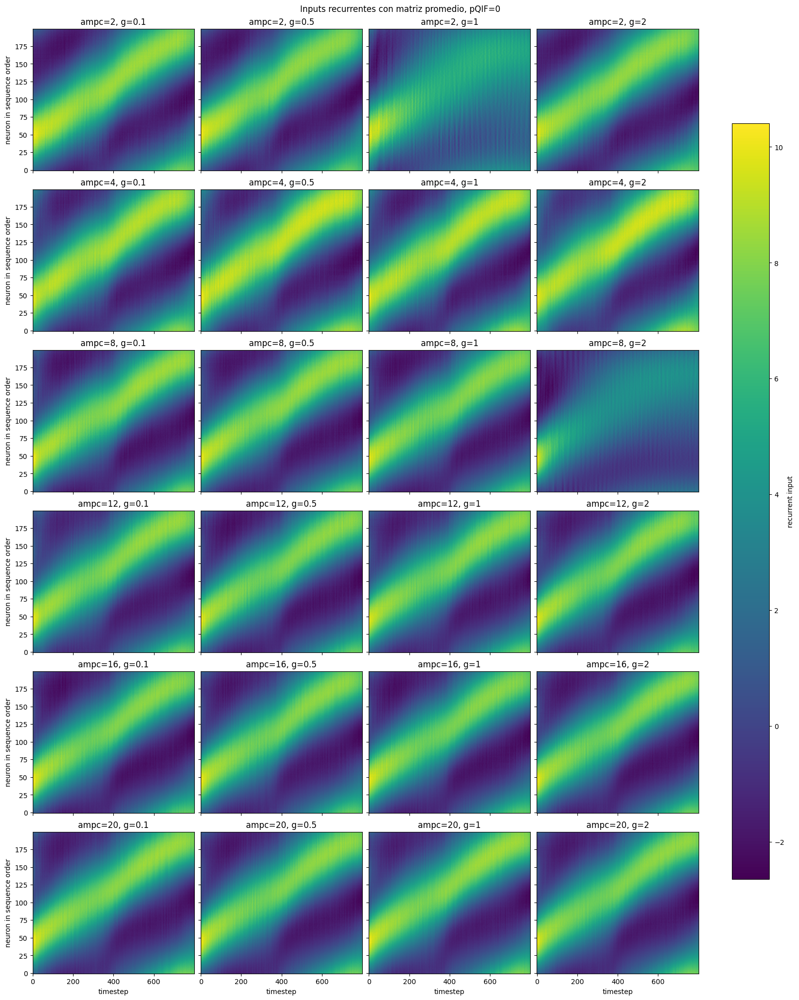

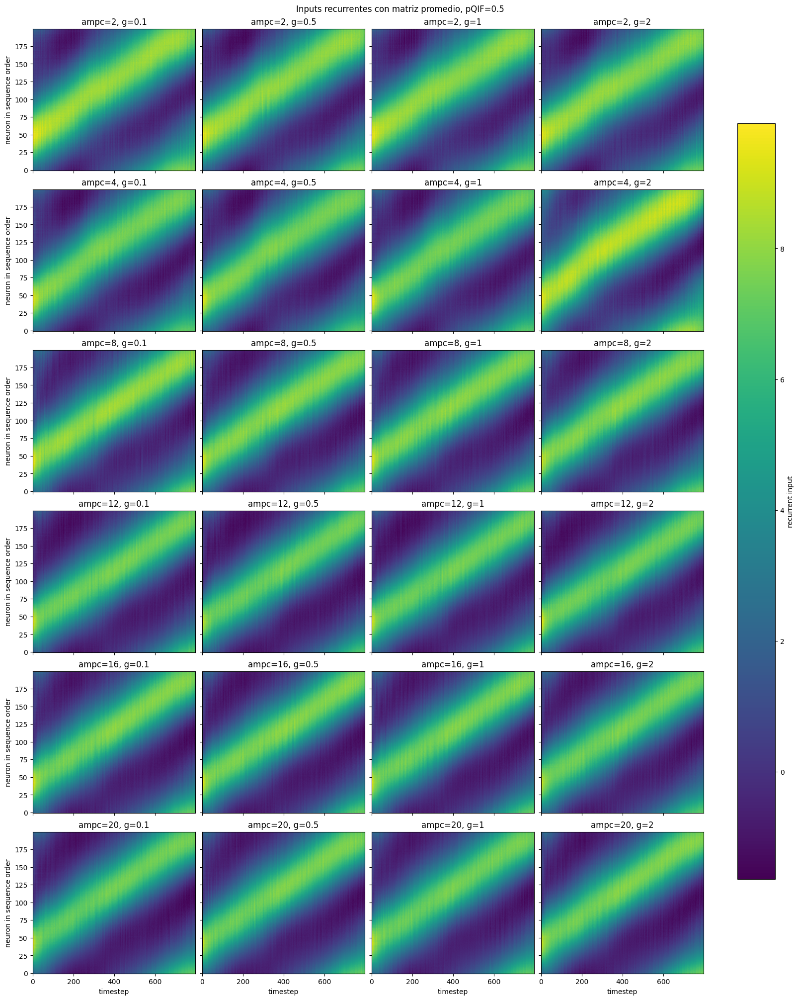

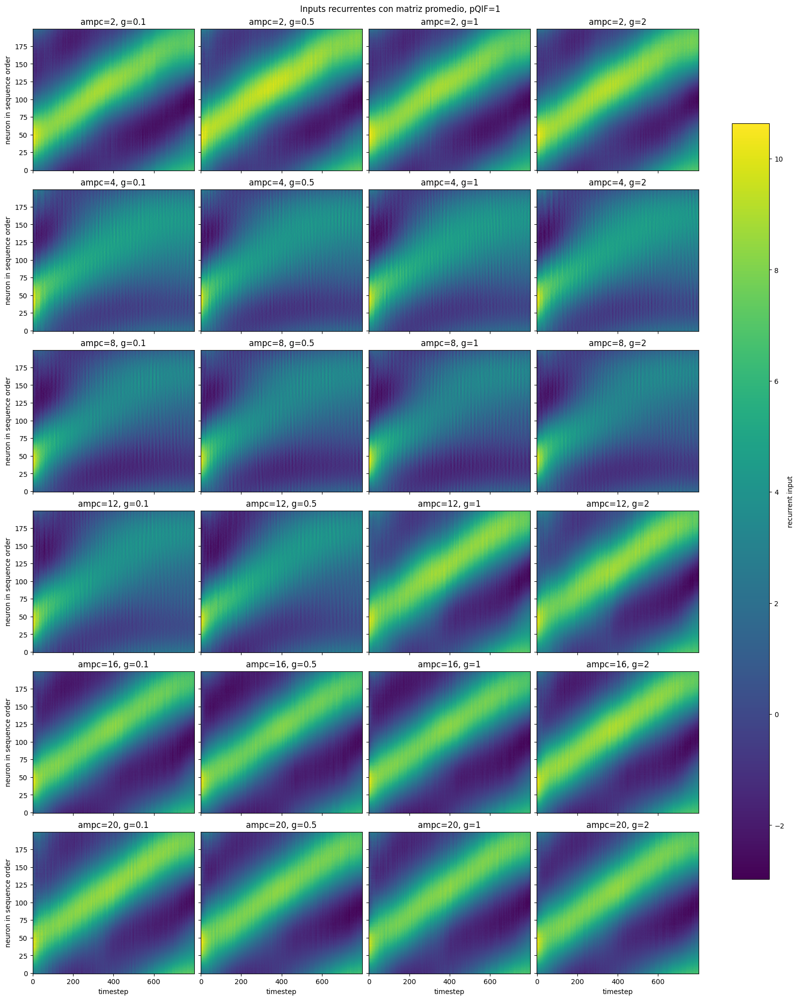

In [6]:
for pqif in PQIFS:
    fig, axes = plt.subplots(len(AMPLITUDES), len(GSYNS), figsize=(16, 20), sharex=True, sharey=True, constrained_layout=True)
    for row, amplitude in enumerate(AMPLITUDES):
        for col, gsyn in enumerate(GSYNS):
            folder = source_dir(amplitude, gsyn)
            data = np.load(folder / f"test_inputs_pqif_{pqif:g}.npz")["inputs"].astype(float)
            order = sequence_order(amplitude, gsyn)
            values = data[ITSTIM:ITMAX].T[order]
            ax = axes[row, col]
            image = ax.imshow(values, aspect="auto", origin="lower", cmap="viridis")
            ax.set_title(f"ampc={amplitude:g}, g={gsyn:g}")
            if row == len(AMPLITUDES)-1: ax.set_xlabel("timestep")
            if col == 0: ax.set_ylabel("neuron in sequence order")
    fig.suptitle(f"Inputs recurrentes con matriz promedio, pQIF={pqif:g}")
    fig.colorbar(image, ax=axes, label="recurrent input", shrink=0.8)
    fig.savefig(OUTPUT / f"average_inputs_pqif_{pqif:g}.png", dpi=180)
    plt.show()


In [7]:
print("R2 recurrent input")
print(r2.pivot_table(index=["current_amplitude","gsyn"], columns="pqif", values="r2_recurrent_input").round(3).to_string())
print("\nR2 output")
print(r2.pivot_table(index=["current_amplitude","gsyn"], columns="pqif", values="r2_output").round(3).to_string())
print(f"Saved plots to {OUTPUT}")


R2 recurrent input
pqif                      0.0    0.5    1.0
current_amplitude gsyn                     
2                 0.1   0.785  0.772  0.868
                  0.5   0.725  0.837  0.845
                  1.0   0.612  0.773  0.875
                  2.0   0.707  0.833  0.875
4                 0.1   0.779  0.835  0.507
                  0.5   0.739  0.857  0.463
                  1.0   0.782  0.887  0.519
                  2.0   0.774  0.743  0.513
8                 0.1   0.860  0.964  0.499
                  0.5   0.813  0.946  0.459
                  1.0   0.843  0.947  0.449
                  2.0   0.614  0.938  0.466
12                0.1   0.833  0.960  0.571
                  0.5   0.868  0.960  0.658
                  1.0   0.872  0.956  0.911
                  2.0   0.844  0.956  0.919
16                0.1   0.870  0.960  0.920
                  0.5   0.865  0.970  0.921
                  1.0   0.876  0.971  0.919
                  2.0   0.881  0.961  0.913
20           